In [472]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb

In [243]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

stores = pd.read_csv('stores.csv')
oil = pd.read_csv('oil.csv')

In [199]:
train.head(3)

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0


In [200]:
test.head(3)

,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2


In [201]:
stores.head(3)

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8


In [377]:
oil["dcoilwtico"] = oil["dcoilwtico"].interpolate(method='linear',limit_direction='both')
oil.head(3)

,date,dcoilwtico
0,2013-01-01,93.14
1,2013-01-02,93.14
2,2013-01-03,92.97


In [244]:
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])

new_year_mask = (train['date'].dt.month == 1) & (train['date'].dt.day == 1)
train.loc[new_year_mask, 'sales'] = 0

train['sales'] = np.log1p(train['sales'])
test['sales'] = np.nan

In [251]:
transactions = pd.read_csv('transactions.csv')
transactions['date'] = pd.to_datetime(transactions['date'])
transactions.head(3)

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358


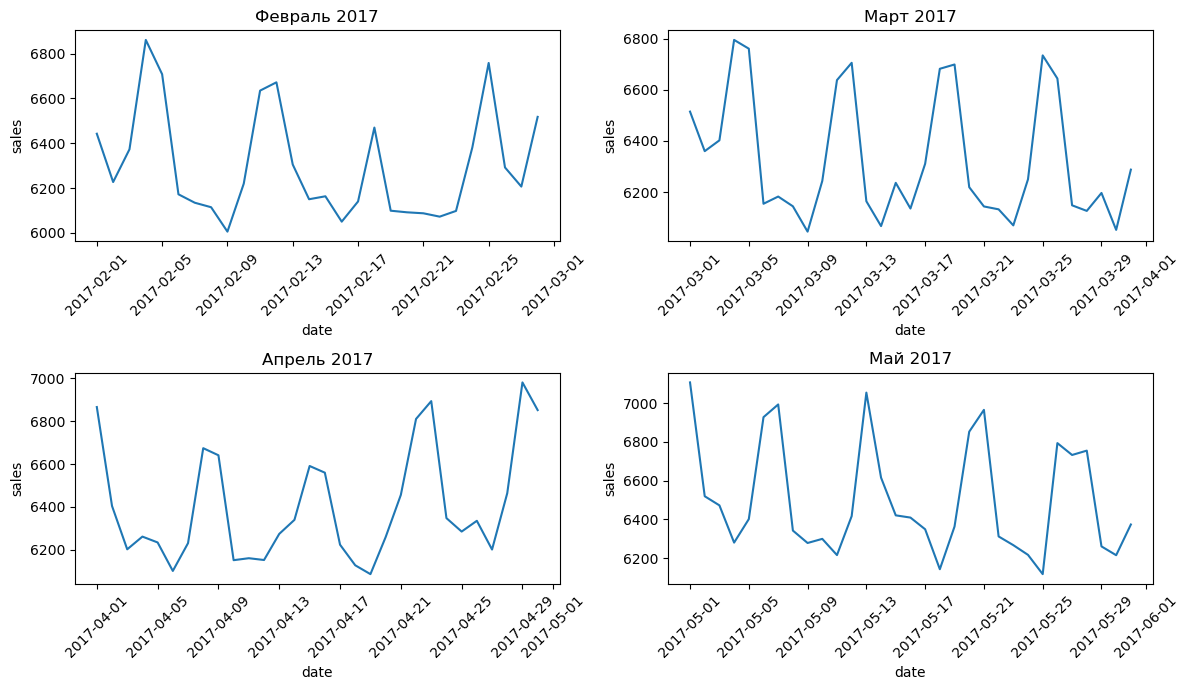

In [449]:
train_2017_2 = (train[(train['date'].dt.year==2017) & (train['date'].dt.month==2)]
        .groupby('date')['sales'].sum().reset_index())
train_2017_3 = (train[(train['date'].dt.year==2017) & (train['date'].dt.month==3)]
        .groupby('date')['sales'].sum().reset_index())
train_2017_4 = (train[(train['date'].dt.year==2017) & (train['date'].dt.month==4)]
        .groupby('date')['sales'].sum().reset_index())
train_2017_5 = (train[(train['date'].dt.year==2017) & (train['date'].dt.month==5)]
        .groupby('date')['sales'].sum().reset_index())

fig, ((ax_2,ax_3), (ax_4,ax_5)) = plt.subplots(2, 2, figsize=(12, 7))

sns.lineplot(data=train_2017_2, x='date', y='sales', ax=ax_2)
ax_2.tick_params(axis='x', rotation=45)
ax_2.set_title('Февраль 2017')

sns.lineplot(data=train_2017_3, x='date', y='sales', ax=ax_3)
ax_3.tick_params(axis='x', rotation=45)
ax_3.set_title('Март 2017')

sns.lineplot(data=train_2017_4, x='date', y='sales', ax=ax_4)
ax_4.tick_params(axis='x', rotation=45)
ax_4.set_title('Апрель 2017')

sns.lineplot(data=train_2017_5, x='date', y='sales', ax=ax_5)
ax_5.tick_params(axis='x', rotation=45)
ax_5.set_title('Май 2017')

plt.tight_layout()
plt.show()

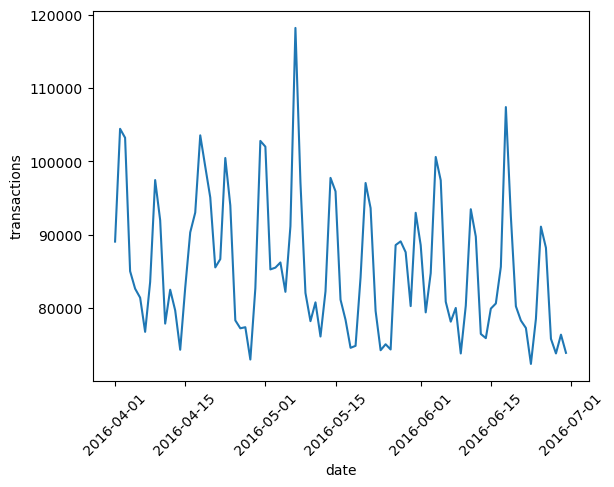

In [259]:
transactions_2016 = (transactions[
        (transactions['date'].dt.year==2016) & 
        (transactions['date'].dt.month>=4) & 
        (transactions['date'].dt.month<=6)]
        .groupby('date')['transactions'].sum().reset_index())

ax = sns.lineplot(data=transactions_2016, x=transactions_2016['date'], y=transactions_2016['transactions'])
ax.tick_params(axis='x', rotation=45)

In [204]:
holidays = pd.read_csv('holidays_events.csv')
holidays = holidays[holidays['transferred'] == False]

holidays.head(3)

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False


In [322]:
national = (holidays[holidays['locale'] == 'National'][['date', 'description']]
            .rename(columns={'description': 'national_holiday'}))
regional = (holidays[holidays['locale'] == 'Regional'][['date', 'locale_name', 'description']]
            .rename(columns={'locale_name': 'state', 'description': 'regional_holiday'}))
local = (holidays[holidays['locale'] == 'Local'][['date', 'locale_name', 'description']]
            .rename(columns={'locale_name': 'city', 'description': 'local_holiday'}))

national.drop_duplicates(subset=['date'], inplace=True)
regional.drop_duplicates(subset=['date', 'state'], inplace=True)
local.drop_duplicates(subset=['date', 'city'], inplace=True)

national['date'] = pd.to_datetime(national['date'])
regional['date'] = pd.to_datetime(regional['date'])
local['date'] = pd.to_datetime(local['date'])

In [436]:
full_df = pd.concat([train, test], ignore_index=True)
full_df = full_df.sort_values(['store_nbr', 'family', 'date']).reset_index(drop=True)

oil['date'] = pd.to_datetime(oil['date'])

full_df = full_df.merge(stores, on='store_nbr', how='left')
full_df = full_df.merge(oil, on='date', how='left')
full_df['dcoilwtico'] = full_df['dcoilwtico'].ffill().bfill()

full_df = full_df.merge(national, on='date', how='left')
full_df = full_df.merge(regional, on=['date', 'state'], how='left')
full_df = full_df.merge(local, on=['date', 'city'], how='left')

full_df['national_holiday'] = full_df['national_holiday'].notna().astype(int)
full_df['regional_holiday'] = full_df['regional_holiday'].notna().astype(int)
full_df['local_holiday'] = full_df['local_holiday'].notna().astype(int)

In [437]:
full_df.head(5)

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico,national_holiday,regional_holiday,local_holiday
0,0,2013-01-01,1,AUTOMOTIVE,0.000000,0,Quito,Pichincha,D,13,93.14,1,0,0
1,1782,2013-01-02,1,AUTOMOTIVE,1.098612,0,Quito,Pichincha,D,13,93.14,0,0,0
2,3564,2013-01-03,1,AUTOMOTIVE,1.386294,0,Quito,Pichincha,D,13,92.97,0,0,0
3,5346,2013-01-04,1,AUTOMOTIVE,1.386294,0,Quito,Pichincha,D,13,93.12,0,0,0
4,7128,2013-01-05,1,AUTOMOTIVE,1.791759,0,Quito,Pichincha,D,13,93.12,1,0,0


In [438]:
full_df['month'] = full_df['date'].dt.month
full_df['day'] = full_df['date'].dt.day
full_df['dayofweek'] = full_df['date'].dt.dayofweek
full_df['dayofyear'] = full_df['date'].dt.dayofyear
full_df['is_weekend'] = full_df['dayofweek'].isin([5, 6]).astype(int)

last_day_of_month = (full_df['date'] + pd.offsets.MonthEnd(0)).dt.day
full_df['days_to_payday'] = np.where(full_df['day'] <= 15, 15 - full_df['day'], last_day_of_month - full_df['day'])
full_df['days_since_payday'] = np.where(full_df['day']>=15, full_df['day']-15, full_df['day'])

In [439]:
full_df.head(3)

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,...,national_holiday,regional_holiday,local_holiday,month,day,dayofweek,dayofyear,is_weekend,days_to_payday,days_since_payday
0,0,2013-01-01,1,AUTOMOTIVE,0.000000,0,Quito,Pichincha,D,13,...,1,0,0,1,1,1,1,0,14,1
1,1782,2013-01-02,1,AUTOMOTIVE,1.098612,0,Quito,Pichincha,D,13,...,0,0,0,1,2,2,2,0,13,2
2,3564,2013-01-03,1,AUTOMOTIVE,1.386294,0,Quito,Pichincha,D,13,...,0,0,0,1,3,3,3,0,12,3


In [440]:
full_df['lag_16'] = full_df.groupby(['store_nbr', 'family'])['sales'].shift(16)
full_df['lag_21'] = full_df.groupby(['store_nbr', 'family'])['sales'].shift(21)
full_df['lag_28'] = full_df.groupby(['store_nbr', 'family'])['sales'].shift(28)

full_df['rolling_mean_7'] = full_df.groupby(['store_nbr', 'family'])['lag_16'].transform(lambda x: x.rolling(7, min_periods=1).mean())
full_df['rolling_mean_14'] = full_df.groupby(['store_nbr', 'family'])['lag_16'].transform(lambda x: x.rolling(14, min_periods=1).mean())
full_df['rolling_mean_30'] = full_df.groupby(['store_nbr', 'family'])['lag_16'].transform(lambda x: x.rolling(30, min_periods=1).mean())

full_df['onpromotion_rolling_7'] = (full_df.groupby(['store_nbr', 'family'])['onpromotion']
        .transform(lambda x: x.shift(16).rolling(7, min_periods=1).mean()))
full_df['dcoilwtico_rolling_7'] = (full_df.groupby(['store_nbr', 'family'])['dcoilwtico']
        .transform(lambda x: x.shift(16).rolling(7, min_periods=1).mean()))

In [444]:
train_final = full_df[(full_df['date']<='2017-08-15') & (full_df['date']>='2017-01-01')].copy()
test_final = full_df[full_df['date']>='2017-08-16'].copy()

train_final = train_final.dropna(subset=['rolling_mean_30']).reset_index(drop=True)
test_final = test_final.drop(columns=['sales'])

valid_start_date = '2017-07-31'

X_train = train_final[train_final['date'] < valid_start_date].drop(columns=['id', 'sales', 'date'], errors='ignore')
y_train = train_final[train_final['date'] < valid_start_date]['sales']

X_val = train_final[train_final['date'] >= valid_start_date].drop(columns=['id', 'sales', 'date'], errors='ignore')
y_val = train_final[train_final['date'] >= valid_start_date]['sales']

for col in ['store_nbr', 'family', 'city', 'state', 'type', 'cluster', 'month']:
    X_train[col] = X_train[col].astype('category')
    X_val[col] = X_val[col].astype('category')

In [475]:
model_lgb = lgb.LGBMRegressor(n_estimators=4000,
                              learning_rate=0.02,
                              objective='regression',
                              metric='rmse',
                              num_leaves=128,
                              max_depth=-1,
                              subsample=0.8,
                              colsample_bytree=0.8,
                              reg_alpha=0.1,
                              reg_lambda=1.0,
                              random_state=42,
                              verbose=-1)

model_lgb.fit(X_train, y_train,
              eval_set=[(X_val, y_val)],
              eval_metric='rmse', 
              callbacks=[
                  lgb.early_stopping(stopping_rounds=50, verbose=True), 
                  lgb.log_evaluation(period=250)])

C:\Users\Victor\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[250]	valid_0's rmse: 0.416356
[500]	valid_0's rmse: 0.409059
[750]	valid_0's rmse: 0.407697
Early stopping, best iteration is:
[792]	valid_0's rmse: 0.407444


,boosting_type,'gbdt'
,num_leaves,128
,max_depth,-1
,learning_rate,0.02
,n_estimators,4000
,subsample_for_bin,200000
,objective,'regression'
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [476]:
X_full = pd.concat([X_train, X_val], axis=0)
y_full = pd.concat([y_train, y_val], axis=0)

for col in ['store_nbr', 'family', 'city', 'state', 'type', 'cluster', 'month']:
    X_full[col] = X_full[col].astype('category')

In [477]:
best_iter_lgb = model_lgb.best_iteration_
final_model = lgb.LGBMRegressor(n_estimators=best_iter_lgb+50, 
                                learning_rate=0.02, 
                                objective='regression', 
                                metric='rmse',
                                num_leaves=128,
                                max_depth=-1,
                                subsample=0.8,
                                colsample_bytree=0.8,
                                reg_alpha=0.1,
                                reg_lambda=1.0,
                                random_state=42)

final_model.fit(X_full, y_full)

,boosting_type,'gbdt'
,num_leaves,128
,max_depth,-1
,learning_rate,0.02
,n_estimators,842
,subsample_for_bin,200000
,objective,'regression'
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [478]:
X_test = test_final.drop(columns=['id', 'date'])

for col in ['store_nbr', 'family', 'city', 'state', 'type', 'cluster', 'month']:
    X_test[col] = X_test[col].astype('category')

pred_lgb = final_model.predict(X_test)
pred_lgb = np.clip(pred_lgb, 0, None)
pred_lgb = np.expm1(pred_lgb)

In [479]:
preds_df = pd.DataFrame({
    'id': test_final['id'].astype(int),
    'sales': pred_lgb})

last_days_train = train_final[train_final['date'] >= '2017-07-25']
sales_check = last_days_train.groupby(['store_nbr', 'family'])['sales'].sum().reset_index()
dead_products = sales_check[sales_check['sales'] < 0.01][['store_nbr', 'family']]
dead_products['is_dead'] = True

original_test = pd.read_csv('test.csv')

preds_df = preds_df.merge(test_final[['id', 'store_nbr', 'family']], on='id', how='left')
preds_df = preds_df.merge(dead_products, on=['store_nbr', 'family'], how='left')
preds_df.loc[preds_df['is_dead'] == True, 'sales'] = 0

submit = original_test[['id']].merge(preds_df[['id', 'sales']], on='id', how='left')
submit['sales'] = submit['sales'].fillna(0)

submit.to_csv('submission_6.csv', index=False)